# Задача №4: итоговый пайплайн

Пайплайн валидирует панель JOLTS, строит шестимесячный прогноз
Theta с интервалами и сохраняет SeasonalNaive как baseline.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import Image, display, Markdown

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from scripts.forecast_pipeline import load_panel, validate_panel
from scripts.task4_pipeline_tests import run_task4

/usr/local/Caskroom/miniconda/base/envs/timeseries/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Входные данные и проверки

In [2]:
data = load_panel(ROOT / "data/processed/total_separations_nf.csv")
validation = validate_panel(data)
validation

{'n_series': 9,
 'n_rows': 2745,
 'min_date': '2000-12-01',
 'max_date': '2026-04-01',
 'min_series_length': 305,
 'max_series_length': 305}

Проверяются обязательные поля, пропуски, дубликаты, типы,
непрерывность месячной шкалы и достаточная длина истории.

## Полный запуск

In [3]:
result = run_task4()
forecast = result["forecast"]
tests = result["tests"]
comparison = result["comparison"]

## Сравнение 15 моделей

In [4]:
comparison[
    ["model", "family", "mase", "smape", "bias"]
].round(3)

,model,family,mase,smape,bias
0,Theta,Statistical,0.719,8.407,13.161
1,AutoTheta,Statistical,0.722,8.416,13.118
9,NHITS,DL,0.757,8.967,9.458
2,ARIMA_manual,Statistical,0.758,8.838,16.817
3,SeasonalNaive,Statistical,0.772,9.120,17.829
4,ETS_manual,Statistical,0.777,9.277,10.072
5,AutoETS,Statistical,0.802,9.377,8.033
6,AutoARIMA,Statistical,0.809,9.338,21.900
10,MLP,DL,0.826,9.583,16.180
11,RandomForest,ML,0.863,10.103,32.570


## Результаты тестирования

In [5]:
tests

,test,passed,details
0,input_schema_and_frequency,True,"{""n_series"": 9, ""n_rows"": 2745, ""min_date"": ""2..."
1,forecast_shape,True,"rows=54, expected=54"
2,interval_order,True,lo95 <= lo80 <= point <= hi80 <= hi95
3,duplicate_rejection,True,A duplicated time-series key must raise ValueE...
4,monthly_gap_rejection,True,A missing month must raise ValueError
5,theta_mase_below_one,True,Theta MASE=0.719
6,theta_beats_seasonal_baseline,True,"Theta=0.719, SeasonalNaive=0.772"
7,theta_best_aggregate_model,True,"best=Theta, NHITS=0.757"
8,baseline_difference_is_nonsignificant,True,Wilcoxon Holm-adjusted p=0.441; Theta practica...
9,pipeline_runtime_under_30_seconds,True,total_seconds=0.843


## Метаданные запуска

In [6]:
print(json.dumps(result["metadata"], ensure_ascii=False, indent=2))

{
  "generated_at_utc": "2026-06-08T16:30:01.239688+00:00",
  "data_path": "/Users/vova/Library/Mobile Documents/iCloud~md~obsidian/Documents/Wyziq/Netology & URFU/2 семестр/08 Анализ временных рядов/ДЗ/data/processed/total_separations_nf.csv",
  "data_sha256": "841b9514a20eaa3ab043f4cb79c38c69829387c64eb19fc48b973c761019fc0d",
  "frequency": "MS",
  "horizon": 6,
  "selected_model": "Theta",
  "baseline_model": "SeasonalNaive",
  "prediction_intervals": [
    80,
    95
  ],
  "validation": {
    "n_series": 9,
    "n_rows": 2745,
    "min_date": "2000-12-01",
    "max_date": "2026-04-01",
    "min_series_length": 305,
    "max_series_length": 305
  },
  "timing_seconds": {
    "load_and_validation": 0.09498215299390722,
    "forecast_and_validation": 0.42240362500888295,
    "total": 0.5327299810014665
  }
}


## Финальный прогноз

In [7]:
forecast.round(2)

/var/folders/dw/d15l4g8x2bz2syn5f_y3_qkm0000gn/T/ipykernel_43022/2280461755.py:1: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  forecast.round(2)


,unique_id,ds,y_hat,lo_80,hi_80,lo_95,hi_95,baseline_y_hat,model,baseline_model
0,Construction,2026-05-01,267.519989,214.059998,332.420013,196.369995,352.260010,309.0,Theta,SeasonalNaive
1,Construction,2026-06-01,266.730011,204.619995,316.559998,184.070007,351.109985,309.0,Theta,SeasonalNaive
2,Construction,2026-07-01,316.070007,228.880005,380.570007,192.350006,422.079987,364.0,Theta,SeasonalNaive
3,Construction,2026-08-01,337.079987,259.619995,398.130005,225.160004,450.170013,415.0,Theta,SeasonalNaive
4,Construction,2026-09-01,298.200012,236.880005,366.540009,208.309998,399.859985,319.0,Theta,SeasonalNaive
5,Construction,2026-10-01,327.100006,254.300003,403.630005,221.529999,439.119995,325.0,Theta,SeasonalNaive
6,Education and Health Services,2026-05-01,771.880005,648.369995,921.830017,607.510010,967.650024,744.0,Theta,SeasonalNaive
7,Education and Health Services,2026-06-01,887.299988,730.530029,1007.059998,665.289978,1083.140015,842.0,Theta,SeasonalNaive
8,Education and Health Services,2026-07-01,906.049988,726.840027,1045.650024,622.280029,1121.300049,835.0,Theta,SeasonalNaive
9,Education and Health Services,2026-08-01,919.039978,748.349976,1049.209961,704.750000,1134.369995,895.0,Theta,SeasonalNaive


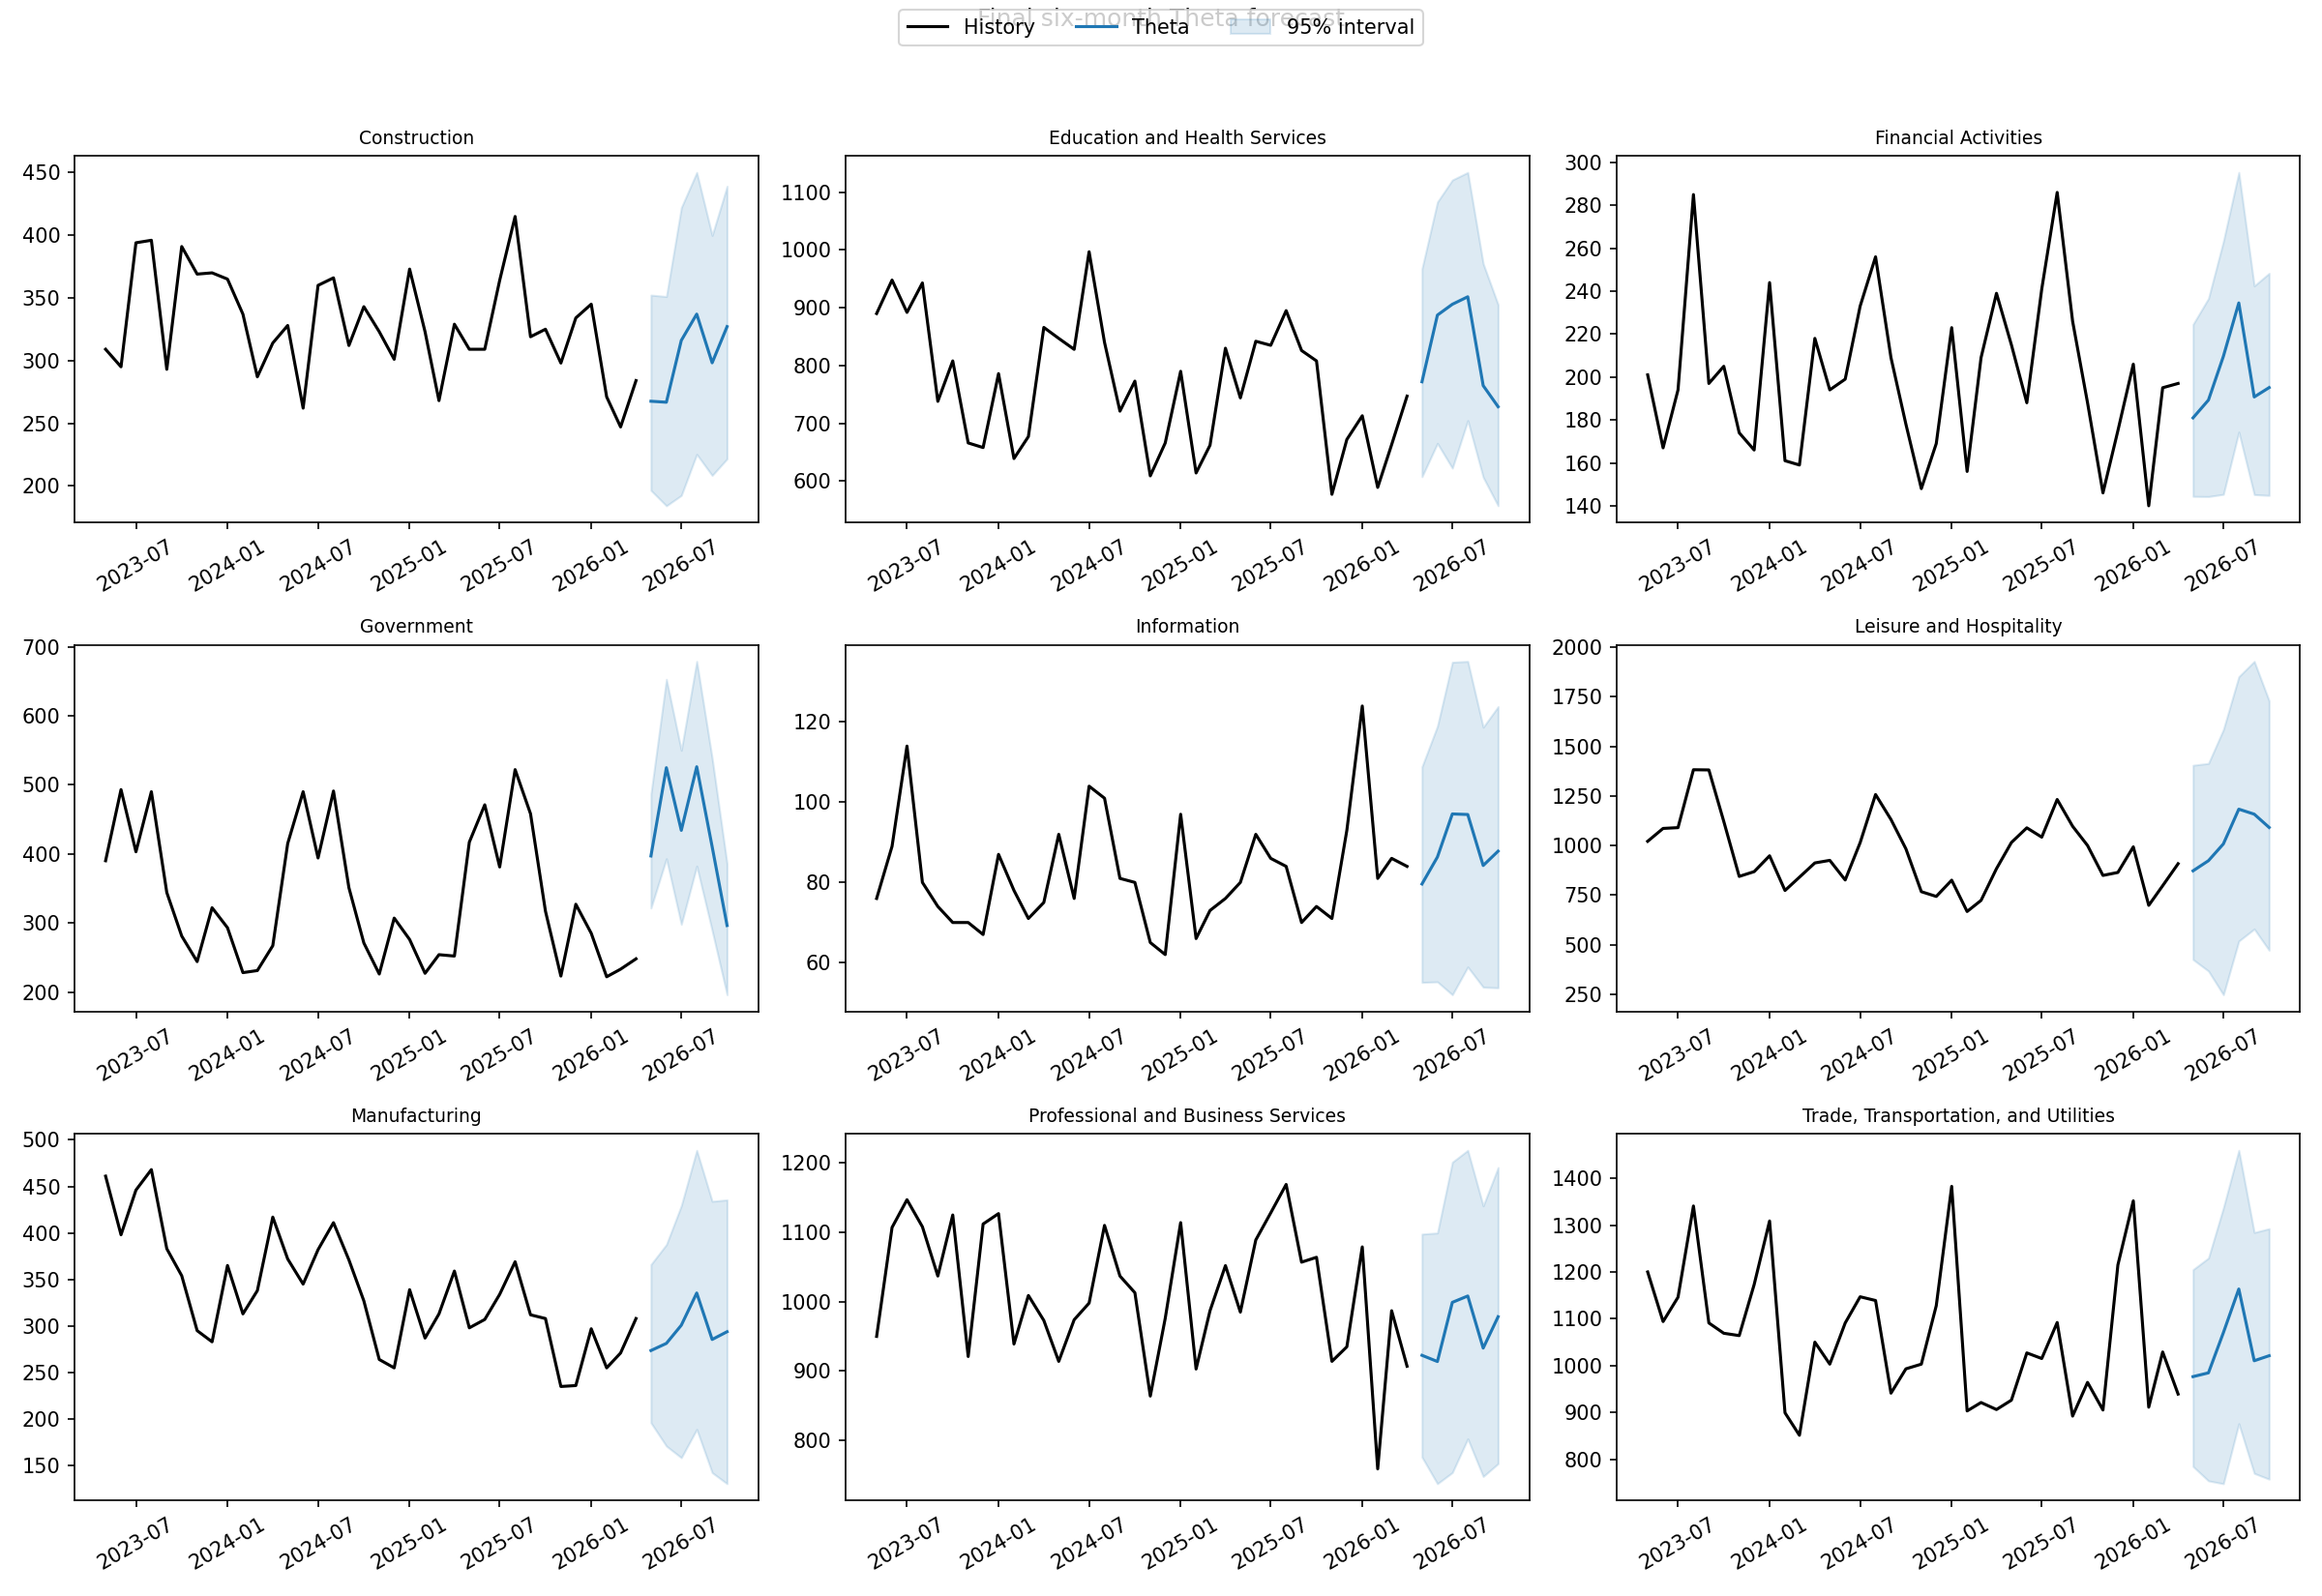

In [8]:
display(
    Image(
        filename=ROOT
        / "figures/task4/final_pipeline_forecast.png"
    )
)

## Итоговый отчет

In [9]:
display(
    Markdown(
        (
            ROOT / "reports/task4/task4_report.md"
        ).read_text(encoding="utf-8")
    )
)

# Задача №4: итоговый пайплайн прогнозирования

## Назначение

Пайплайн прогнозирует общее число увольнений в девяти отраслях США на
следующие шесть месяцев. На вход подается панель `unique_id, ds, y` с
ежемесячной частотой. На выходе для каждой отрасли формируются точечный прогноз
Theta, интервалы 80% и 95% и контрольный прогноз SeasonalNaive.

## Компоненты и обоснование

1. Валидация проверяет схему, типы, пропуски, дубликаты, конечность и
   неотрицательность значений, непрерывность месячной шкалы и наличие не менее
   двух сезонных циклов.
2. `Theta(12)` выбрана по общему rolling-origin backtesting: MASE
   `0.719`. Она лучше SeasonalNaive на `6.9%` и
   лучше лучшей data-driven модели NHITS с MASE `0.757`.
   Одна общая спецификация используется для всех отраслей: отраслевые
   победители выбирались на тех же 36 backtesting-блоках, поэтому их прямое
   включение в pipeline усилило бы selection bias без отдельной контрольной
   выборки.
3. `SeasonalNaive(12)` сохраняется в результате как прозрачный baseline.
4. Интервалы 80% и 95% позволяют оценивать неопределенность, но историческое
   покрытие Theta было консервативным: 0.940 и 0.995.
5. CSV с прогнозом и JSON с контрольной суммой входа, параметрами и временем
   выполнения обеспечивают воспроизводимость запуска.

## Сравнение всех методов

| Модель | Семейство | MASE | sMAPE, % | Bias |
|---|---|---:|---:|---:|
| Theta | Statistical | 0.719 | 8.407 | 13.161 |
| AutoTheta | Statistical | 0.722 | 8.416 | 13.118 |
| NHITS | DL | 0.757 | 8.967 | 9.458 |
| ARIMA_manual | Statistical | 0.758 | 8.838 | 16.817 |
| SeasonalNaive | Statistical | 0.772 | 9.120 | 17.829 |
| ETS_manual | Statistical | 0.777 | 9.277 | 10.072 |
| AutoETS | Statistical | 0.802 | 9.377 | 8.033 |
| AutoARIMA | Statistical | 0.809 | 9.338 | 21.900 |
| MLP | DL | 0.826 | 9.583 | 16.180 |
| RandomForest | ML | 0.863 | 10.103 | 32.570 |
| LightGBM | ML | 0.870 | 9.820 | 30.847 |
| Ridge | ML | 0.968 | 11.356 | 32.414 |
| Prophet_manual | Statistical | 1.202 | 13.319 | 63.222 |
| LSTM | DL | 1.261 | 14.342 | 24.444 |
| Naive | Statistical | 1.271 | 14.698 | 3.569 |

## Тестирование пайплайна

| Проверка | Результат | Детали |
|---|---|---|
| input_schema_and_frequency | PASS | {"n_series": 9, "n_rows": 2745, "min_date": "2000-12-01", "max_date": "2026-04-01", "min_series_length": 305, "max_series_length": 305} |
| forecast_shape | PASS | rows=54, expected=54 |
| interval_order | PASS | lo95 <= lo80 <= point <= hi80 <= hi95 |
| duplicate_rejection | PASS | A duplicated time-series key must raise ValueError |
| monthly_gap_rejection | PASS | A missing month must raise ValueError |
| theta_mase_below_one | PASS | Theta MASE=0.719 |
| theta_beats_seasonal_baseline | PASS | Theta=0.719, SeasonalNaive=0.772 |
| theta_best_aggregate_model | PASS | best=Theta, NHITS=0.757 |
| baseline_difference_is_nonsignificant | PASS | Wilcoxon Holm-adjusted p=0.441; Theta practical gain is reported as not statistically significant |
| pipeline_runtime_under_30_seconds | PASS | total_seconds=0.843 |

Полное время запуска: `0.533` с; прогнозирование и проверка:
`0.422` с. Порог performance-теста установлен
в 30 секунд для текущей панели из девяти рядов.

Статистическое преимущество Theta над SeasonalNaive не подтверждено после
Holm-коррекции (`p = 0.441`). Поэтому выбор основан на практическом общем
MASE, а не трактуется как доказанное превосходство в генеральной совокупности.

![Финальный прогноз](../../figures/task4/final_pipeline_forecast.png)

## Вывод по задаче №4

Пайплайн автоматически валидирует данные, обучает основную и контрольную
модели, строит 54 прогноза с вероятностными интервалами и сохраняет артефакты
запуска. Все функциональные, статистические и performance-проверки пройдены.

## Общее заключение

Исследована ежемесячная несезонно скорректированная статистика JOLTS по общему
числу увольнений в девяти крупных отраслях США за декабрь 2000 — апрель 2026
года. Цель работы — offline-прогноз на шесть месяцев. Данные не содержат
пропусков и имеют выраженную годовую сезонность; после первой разности все
девять рядов проходят совместную проверку стационарности.

В rolling-origin backtesting с четырьмя окнами сравнивались 15 моделей:
девять статистических, три ML и три DL. Лучший результат показала Theta:
MASE `0.719`, sMAPE `8.407%`. SeasonalNaive имеет
MASE `0.772`, лучший data-driven метод NHITS —
`0.757`. Преимущество Theta над baseline составляет
`6.9%`, но статистически незначимо после поправки на
множественные сравнения. Поэтому в эксплуатации одновременно сохраняются
Theta и SeasonalNaive, а качество следует повторно проверять при каждом
обновлении данных и смене рыночного режима.
